# Project 3 on Machine Learning: three paths

**Data Analysis and Machine Learning FYS-STK3155/FYS4155, University of Oslo, fall 2026**

**Deadline: December 11 (midnight), 2026.** Published November 10, 2026.

This notebook is the Jupyter version of the project text (`Project3.pdf`). You
choose **one** of the three paths: A) differential equations with neural networks,
B) a classification study with several methods, C) the statistics and mathematics
behind the methods. The code cells are *starting points*, not solutions: they show
how to load Fashion-MNIST for path B and how to generate the Gaussian-mixture data
with a known Bayes error for path C. Everything else is yours to write.


## Deliverables

First, join a group in Canvas with your group partners. Pick an available group for Project 3 in the **People** page.

In Canvas, deliver as a group and include:

- A PDF of your report which follows the guidelines covered below. Additional requirements include:

  - It should be around 5000 words; use the word counter in Overleaf for this. This often corresponds to 10–12 pages. References and appendices are excluded from the word count. Appendices should read like regular text and can include additional calculations you have made.

  - It should include around 10–15 figures. You can include more figures in appendices and/or as supplemental material in your repository. Including additional figures in appendices requires also that you add text which explains the additional material.

- A comment linking to your GitHub repository (or a folder in one of your GitHub repositories) for this project. The repository must include

  - a PDF file of the report;

  - a folder named `Code`, where you put Python files for your functions and notebooks for reproducing your results. Remember to use a seed for generating random data and for train-test splits when generating final results;

  - a `README` file with the names of the group members, a short description of the project, a description of how to install the required packages to run your code (from a `requirements.txt` file or similar, such as a plain text description), and the names and descriptions of the various notebooks in the `Code` folder and the results they produce.


## Path B: A classification study with several methods

This path follows the structure of a typical applied machine-learning study: one classification problem, several methods, one honest comparison. The methods must include **at least three** of those we have discussed during the semester – logistic regression, feed-forward neural networks, convolutional neural networks, recurrent neural networks, decision trees, bagging, random forests, boosting and gradient boosting – and among the three there should be **at least one neural network** (feed-forward or convolutional) and **at least one tree-based ensemble** (random forest, gradient boosting or XGBoost). A natural triple for an image data set is gradient boosting, a feed-forward neural network and a convolutional network; for a tabular data set it could be logistic regression, a random forest and a gradient-boosting method. Logistic regression is cheap and we recommend that you always include it as the baseline, as in project 2. Support vector machines (Chapter 6 of the lecture notes) are welcome as an additional method, although they have not been covered in the lectures.


### The default data set: Fashion-MNIST

Our default proposal is **Fashion-MNIST** (Xiao, Rasul and Vollgraf, arXiv:1708.07747 (2017)), see <https://github.com/zalandoresearch/fashion-mnist>. It consists of $70\,000$ grey-scale images of $28\times 28$ pixels of clothing items from the Zalando catalogue, in ten classes (T-shirt/top, trouser, pullover, dress, coat, sandal, shirt, sneaker, bag, ankle boot), with the canonical split into $60\,000$ training and $10\,000$ test images. It has exactly the format of MNIST, so your code from project 2 runs on it unchanged, but it is a harder problem: on the benchmark page of the repository, logistic regression on the raw pixels reaches an accuracy of roughly $0.84$, random forests and gradient boosting roughly $0.87$–$0.89$, a feed-forward network roughly $0.88$–$0.90$, and convolutional networks between $0.91$ and $0.94$ depending on their size. The classes shirt, T-shirt/top, pullover and coat are confused with each other by every method, which makes the confusion matrix genuinely informative.

The data can be read with the loaders of the libraries, for example


In [1]:
# PyTorch
from torchvision.datasets import FashionMNIST
train = FashionMNIST(root="data", train=True, download=True)
test = FashionMNIST(root="data", train=False, download=True)

or downloaded as the four compressed files described on the GitHub page. As in project 2, flatten the images to vectors of $784$ features and scale the pixel values to $[0,1]$ for the feed-forward network, the logistic regression and the tree-based methods (trees do not need the scaling, but it does no harm), and keep the $28\times 28$ shape for the convolutional network. Use the canonical split as intended: all training, model selection and hyperparameter tuning on the training data (a validation split or cross-validation), the test set once at the end. If you are limited by computing power, you may tune on a subset of the training data, but the numbers you report should be for the full test set. Cite the data set.


### Other data sets

You can replace Fashion-MNIST with a data set of your own choice, preferably one that has been studied in the literature so that you have results to compare with. Possibilities are CIFAR-10 (<https://www.cs.toronto.edu/~kriz/cifar.html>, $60\,000$ colour images in ten classes, harder than Fashion-MNIST and more demanding for the convolutional network), tabular classification sets from the UCI repository (<https://archive.ics.uci.edu/ml/index.php>; for example the covertype, adult, wine-quality or spambase data, where the tree-based methods are usually the strongest and the convolutional network is replaced by a feed-forward one), sequence data where a recurrent network is natural (Chapter 11), or data from your own field of study. Kaggle (<https://www.kaggle.com/datasets>) hosts many documented data sets with published analyses. If you use your own data, write to us before you start. Binary classification problems are allowed if the data set is rich enough; the quality measures of Chapter 5 then apply directly.


### Path B, part a): The data

Describe how the data were produced and place them in a proper context: what is a sample, what are the features, what are the classes and how balanced are they? Show examples. Describe the preprocessing (scaling, flattening or reshaping, one-hot encoding of the labels) and the split into training, validation and test data, and explain why you split as you do. Cite the source of the data and the articles that have analyzed them before.


In [2]:
%load_ext autoreload
%autoreload 2

import os
import numpy as np
import pandas as pd

from cnn import CNN, Net, set_seed, run_cnn, save_cnn, load_net
from dataset import load_fashion_mnist, make_loaders
from tuning import grid_search, best_row, keep_best
from plots import heatmap

set_seed(0)

full, train, val, test = load_fashion_mnist()        # also saves the split indices in data/
train_loader, val_loader, test_loader = make_loaders(train, val, test)

### Path B, part b): The methods

Explain the basics of the methods you have chosen to work with. This is the theory part of your report: the model, its cost function, how it is trained, which hyperparameters it has and what they do. For a tree-based ensemble this means the splitting criterion (Gini index or entropy), bagging and the random feature subset of a forest, or the additive model and the loss of a boosting method (Chapter 7); for the networks the architecture, the activation functions, the softmax output and the cross entropy (Chapters 8 and 10). Explain also the quality measures you will use (Section 5.12 of the lecture notes).


### Path B, part c): Implementation and tests

Describe your algorithms and their implementation, and the tests you have performed. Say which parts are your own code (from project 2 or new) and which parts use Scikit-Learn, TensorFlow/Keras, PyTorch, XGBoost or other libraries. For each method, describe how you searched for the hyperparameters – the learning rate and the regularization for the networks, the depth, number of trees, number of features per split and learning rate for the ensembles – using cross-validation or a validation set (Chapter 3 and week 44), and present the search as heat maps or curves rather than as a list of runs. Report the training times and the number of parameters of each model. Use seeds.


In [3]:
# Quick sanity check (3 epochs): the pipeline runs and val accuracy is far above 10%
model = CNN(conv_layers=[{"out": 16, "k": 5, "pool": 2},
                         {"out": 32, "k": 5, "pool": 2}],
            fc_layers=[128], learning_rate=1e-3, max_epochs=3, patience=3)
history = model.fit(train_loader, val_loader)

print(f"Params: {model.n_params:,} | Time: {model.train_time:.1f}s | Device: {model.device}")
print(f"Epochs run: {len(history)} | Best val acc: {max(h['val_acc'] for h in history):.4f}")

Params: 80,202 | Time: 15.9s | Device: cpu
Epochs run: 3 | Best val acc: 0.8785


In [4]:
RES_CSV = "data/grid_results.csv"
BEST_PT = "data/best_net.pt"
MAX_EPOCHS, PATIENCE, SEED = 30, 4, 0
# NOTE: delete RES_CSV and BEST_PT if you change MAX_EPOCHS, PATIENCE, SEED or the
# content of ARCHS: the resume logic only looks at the parameters of the grid (arch, lr, wd).

ARCHS = {
    "small": dict(conv_layers=[{"out": 8,  "k": 5, "pool": 2},
                               {"out": 16, "k": 5, "pool": 2}], fc_layers=[64]),
    "base":  dict(conv_layers=[{"out": 16, "k": 5, "pool": 2},
                               {"out": 32, "k": 5, "pool": 2}], fc_layers=[128]),
    "deep":  dict(conv_layers=[{"out": 16, "k": 3, "pad": 1},
                               {"out": 32, "k": 3, "pad": 1, "pool": 2},
                               {"out": 64, "k": 3, "pad": 1, "pool": 2}], fc_layers=[128]),
}
LRS = [3e-4, 1e-3, 3e-3, 1e-2]


def run(cfg):
    return run_cnn(cfg, ARCHS, train, val, MAX_EPOCHS, PATIENCE, SEED)


save_best = keep_best(save_cnn(BEST_PT), csv_path=RES_CSV)   # keep only the best weights


def search(grid):
    # Run every configuration of the grid not already in the CSV; returns the whole table
    return grid_search(run, grid, RES_CSV, on_row=save_best)

In [5]:
# Stage 1: architecture x learning rate, no weight decay
df = search({"arch": list(ARCHS), "lr": LRS, "wd": [0.0]})

b1 = best_row(df, wd=0.0)
print(f"Best of stage 1: arch={b1.arch}, lr={b1.lr}, val_acc={b1.val_acc:.4f}")

{'arch': 'small', 'lr': 0.0003, 'wd': 0.0, 'val_acc': 0.8893333333333333, 'val_loss': 0.2980912932952245, 'best_epoch': 27, 'epochs_run': 30, 'n_params': 20522, 'time_s': 131.91207218170166}
{'arch': 'small', 'lr': 0.001, 'wd': 0.0, 'val_acc': 0.9048333333333334, 'val_loss': 0.26042138373851775, 'best_epoch': 22, 'epochs_run': 27, 'n_params': 20522, 'time_s': 117.99174571037292}
{'arch': 'small', 'lr': 0.003, 'wd': 0.0, 'val_acc': 0.9, 'val_loss': 0.2639446784257889, 'best_epoch': 9, 'epochs_run': 14, 'n_params': 20522, 'time_s': 61.748310565948486}
{'arch': 'small', 'lr': 0.01, 'wd': 0.0, 'val_acc': 0.8875, 'val_loss': 0.2974523369471232, 'best_epoch': 6, 'epochs_run': 11, 'n_params': 20522, 'time_s': 48.380677938461304}
{'arch': 'base', 'lr': 0.0003, 'wd': 0.0, 'val_acc': 0.9073333333333333, 'val_loss': 0.26108607117335003, 'best_epoch': 29, 'epochs_run': 30, 'n_params': 80202, 'time_s': 165.7353048324585}
{'arch': 'base', 'lr': 0.001, 'wd': 0.0, 'val_acc': 0.9071666666666667, 'val_l

In [6]:
# Stage 2: lr x weight decay on the best architecture of stage 1 (wd = 0 is already done)
df = search({"arch": [b1.arch], "lr": LRS, "wd": [1e-4, 1e-3]})

bb = best_row(df)
print(f"Best overall: arch={bb.arch}, lr={bb.lr}, wd={bb.wd}, val_acc={bb.val_acc:.4f}")
print(f"Weights of this network are in {BEST_PT}")

{'arch': 'deep', 'lr': 0.0003, 'wd': 0.0001, 'val_acc': 0.9231666666666667, 'val_loss': 0.21661855940024058, 'best_epoch': 19, 'epochs_run': 24, 'n_params': 426122, 'time_s': 338.296826839447}
{'arch': 'deep', 'lr': 0.0003, 'wd': 0.001, 'val_acc': 0.9183333333333333, 'val_loss': 0.22574952936172485, 'best_epoch': 22, 'epochs_run': 27, 'n_params': 426122, 'time_s': 365.84624433517456}
{'arch': 'deep', 'lr': 0.001, 'wd': 0.0001, 'val_acc': 0.9265, 'val_loss': 0.2048549927473068, 'best_epoch': 8, 'epochs_run': 13, 'n_params': 426122, 'time_s': 169.09469723701477}
{'arch': 'deep', 'lr': 0.001, 'wd': 0.001, 'val_acc': 0.9191666666666667, 'val_loss': 0.21329585667451223, 'best_epoch': 8, 'epochs_run': 13, 'n_params': 426122, 'time_s': 169.4676854610443}
{'arch': 'deep', 'lr': 0.003, 'wd': 0.0001, 'val_acc': 0.9258333333333333, 'val_loss': 0.2077610739072164, 'best_epoch': 6, 'epochs_run': 11, 'n_params': 426122, 'time_s': 4849.3166337013245}
{'arch': 'deep', 'lr': 0.003, 'wd': 0.001, 'val_ac

### Path B, part d): Results

Present your results and findings for all methods on the *same* test data: the accuracy with its standard error, the confusion matrix, the per-class precision, recall and $F_1$ score, and one-versus-rest ROC curves with their areas (and cumulative gains curves if you find them useful). Compare the methods with each other, with the logistic-regression baseline, and with the published benchmarks or articles for your data set. Show which classes are confused and look at the misclassified samples; for the trees show the feature importances, for the convolutional network the learned filters or a few feature maps. Discuss whether the differences you see are larger than the uncertainties.


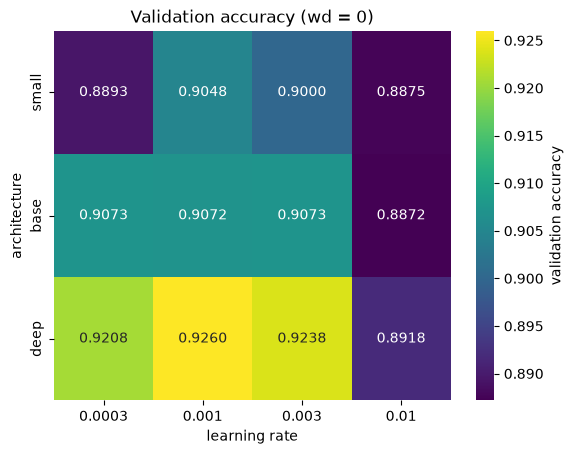

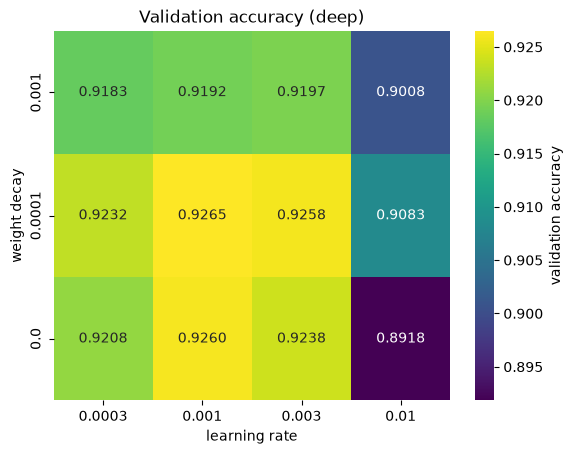

arch     lr     wd  val_acc  val_loss  best_epoch  epochs_run  n_params      time_s
deep 0.0010 0.0001 0.926500  0.204855           8          13  426122.0  169.094697
deep 0.0010 0.0000 0.926000  0.213015           6          11  426122.0  957.783349
deep 0.0030 0.0001 0.925833  0.207761           6          11  426122.0 4849.316634
deep 0.0030 0.0000 0.923833  0.214803           3           8  426122.0  112.362668
deep 0.0003 0.0001 0.923167  0.216619          19          24  426122.0  338.296827
deep 0.0003 0.0000 0.920833  0.214664          17          22  426122.0  328.751827
deep 0.0030 0.0010 0.919667  0.223789           8          13  426122.0  200.517667
deep 0.0010 0.0010 0.919167  0.213296           8          13  426122.0  169.467685
deep 0.0003 0.0010 0.918333  0.225750          22          27  426122.0  365.846244
deep 0.0100 0.0001 0.908333  0.249784           7          12  426122.0  185.102289


In [7]:
# Figure 1: architecture x learning rate (wd = 0)
piv = df[df.wd == 0.0].pivot(index="arch", columns="lr", values="val_acc")
piv = piv.loc[[a for a in ARCHS if a in piv.index]]            # fixed row order
heatmap(piv, "learning rate", "architecture", "Validation accuracy (wd = 0)", "heat_arch_lr")

# Figure 2: learning rate x weight decay on the best architecture
piv = df[df.arch == b1.arch].pivot(index="wd", columns="lr", values="val_acc")
heatmap(piv.sort_index(ascending=False), "learning rate", "weight decay",
        f"Validation accuracy ({b1.arch})", "heat_lr_wd")

# Table: ten best runs. Differences below ~0.004 are within the noise of a single run
# (6000 validation samples), so do not over-interpret the ranking.
# (time_s is NaN for the runs made before train_time was restored in cnn.py)
cols = ["arch", "lr", "wd", "val_acc", "val_loss", "best_epoch", "epochs_run", "n_params", "time_s"]
print(df.sort_values("val_acc", ascending=False)[[c for c in cols if c in df.columns]].head(10).to_string(index=False))

In [8]:
SEEDS = [0, 1, 2, 3, 4]
cfg = {"arch": bb.arch, "lr": bb.lr, "wd": bb.wd}

# Final models: same configuration, different seeds (weight init and shuffling)
models = [run_cnn(cfg, ARCHS, train, val, MAX_EPOCHS, PATIENCE, s)[1] for s in SEEDS]
val_accs = [m.evaluate(val_loader)[1] for m in models]
print(f"val acc: {np.mean(val_accs):.4f} ± {np.std(val_accs, ddof=1):.4f}")
print(f"params: {models[0].n_params:,} | train time: {np.mean([m.train_time for m in models]):.0f} s per model")

val acc: 0.9263 ± 0.0023
params: 426,122 | train time: 215 s per model


In [9]:
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, roc_auc_score

test_accs = [m.evaluate(test_loader)[1] for m in models]
n = len(test)
p = np.mean(test_accs)
print(f"test acc: {p:.4f} ± {np.std(test_accs, ddof=1):.4f} (seeds), "
      f"binomial SE ≈ {np.sqrt(p*(1-p)/n):.4f}")

m = models[int(np.argmax(val_accs))]            # chosen on validation
P, Y = m.predict_proba(test_loader)
pred = P.argmax(1)
print(classification_report(Y, pred, target_names=full.classes, digits=3))
cm = confusion_matrix(Y, pred, normalize="true")   # then sns.heatmap(cm, ...)
print("macro AUC (OvR):", roc_auc_score(Y, P, multi_class="ovr"))

test acc: 0.9194 ± 0.0016 (seeds), binomial SE ≈ 0.0027
              precision    recall  f1-score   support

 T-shirt/top      0.862     0.886     0.874      1000
     Trouser      0.996     0.978     0.987      1000
    Pullover      0.885     0.889     0.887      1000
       Dress      0.882     0.953     0.916      1000
        Coat      0.880     0.888     0.884      1000
      Sandal      0.978     0.986     0.982      1000
       Shirt      0.819     0.722     0.767      1000
     Sneaker      0.984     0.941     0.962      1000
         Bag      0.973     0.988     0.981      1000
  Ankle boot      0.952     0.986     0.969      1000

    accuracy                          0.922     10000
   macro avg      0.921     0.922     0.921     10000
weighted avg      0.921     0.922     0.921     10000

macro AUC (OvR): 0.9953597888888888


### Path B, part e): Critical assessment

Finally, present a critical assessment of the methods you have studied and link your results with the existing literature. Which method is best for your data, at what cost in computing time, data preparation and interpretability? Which would you recommend to somebody facing a similar problem, and what would you try next?


In [10]:
# Your code for path B, part e) here

### Summary of requirements for path B

**Required implementation:** at least three methods of the course, including a neural network and a tree-based ensemble, applied to one classification data set that is not MNIST; a systematic hyperparameter search on training or validation data for each method; the quality measures of Chapter 5 (accuracy, confusion matrix, precision, recall, $F_1$, ROC and AUC).

**Required analysis:** the data in context; the theory of each method; a comparison of all methods on the same test set with uncertainties; a comparison with the published literature or benchmarks; the misclassified classes and samples; the critical assessment of part e).


## Background literature

- The lecture notes of the course at <https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/>: Chapters 2 and 3 (statistics, resampling, linear regression), Chapter 5 (logistic regression and the quality measures of a classifier), Chapter 7 (decision trees, bagging, random forests and boosting), Chapter 8 (neural networks), Chapter 9 (differential equations with neural networks), Chapter 10 (convolutional networks) and Chapter 11 (recurrent networks).

- Hastie, Tibshirani and Friedman, *The Elements of Statistical Learning*, Springer, at <https://hastie.su.domains/ElemStatLearn/>; chapters 7 (model assessment and selection), 9 (trees), 10 (boosting) and 15 (random forests) are the ones for paths B and C.

- Goodfellow, Bengio and Courville, *Deep Learning*, at <https://www.deeplearningbook.org/>, chapters 6–9.

- Raschka et al. at <https://sebastianraschka.com/blog/2022/ml-pytorch-book.html>, chapters 3, 6, 7, 11–14.

- For path A: Lagaris, Likas and Fotiadis, IEEE Trans. Neural Networks **9**, 987 (1998); Raissi, Perdikaris and Karniadakis, J. Comput. Phys. **378**, 686 (2019); Yadav, Yadav and Kumar, *An Introduction to Neural Network Methods for Differential Equations*, Springer (2015).

- For path B: Xiao, Rasul and Vollgraf, *Fashion-MNIST: a Novel Image Dataset for Benchmarking Machine Learning Algorithms*, arXiv:1708.07747 (2017), and the benchmark table at <https://github.com/zalandoresearch/fashion-mnist>.

- For path C: Breiman, *Bagging predictors*, Machine Learning **24**, 123 (1996) and *Random forests*, Machine Learning **45**, 5 (2001); Efron and Tibshirani, *An Introduction to the Bootstrap*, Chapman and Hall (1993); Belkin, Hsu, Ma and Mandal, *Reconciling modern machine-learning practice and the classical bias-variance trade-off*, PNAS **116**, 15849 (2019), for the optional double-descent item.


## Introduction to numerical projects

Here follows a brief recipe and recommendation on how to answer the various questions when preparing your answers.

- Give a short description of the nature of the problem and the eventual numerical methods you have used.

- Describe the algorithm you have used and/or developed. Here you may find it convenient to use pseudocoding. In many cases you can describe the algorithm in the program itself.

- Include the source code of your program. Comment your program properly. You should have the code at your GitHub/GitLab link. You can also place the code in an appendix of your report.

- If possible, try to find analytic solutions, or known limits in order to test your program when developing the code. In this project the analytical solution of the diffusion equation (path A), the published benchmarks (path B) and the closed-form bias, variance and Bayes error (path C) are exactly such tests.

- Include your results either in figure form or in a table. Remember to label your results. All tables and figures should have relevant captions and labels on the axes.

- Try to evaluate the reliability and numerical stability/precision of your results. If possible, include a qualitative and/or quantitative discussion of the numerical stability, eventual loss of precision etc.

- Try to give an interpretation of your results in your answers to the problems.

- Critique: if possible include your comments and reflections about the exercise, whether you felt you learnt something, ideas for improvements and other thoughts you’ve made when solving the exercise. We wish to keep this course at the interactive level and your comments can help us improve it.

- Try to establish a practice where you log your work at the computer lab. You may find such a logbook very handy at later stages in your work, especially when you don’t properly remember what a previous test version of your program did. Here you could also record the time spent on solving the exercise, various algorithms you may have tested or other topics which you feel worthy of mentioning.


## Software and needed installations

If you have Python installed (we recommend Python 3) and you feel pretty familiar with installing different packages, we recommend that you install the following Python packages via `pip` as

> `pip install numpy scipy matplotlib ipython jupyter scikit-learn`  
> `pip install pandas seaborn`  
> `pip install jax jaxlib`

and, depending on your path, `tensorflow` or `torch` (and `torchvision` for the data loaders) for the neural networks of paths A and B, and `xgboost` if you choose it for the gradient boosting of path B. For Python 3, replace `pip` with `pip3` where needed.

For OSX users we recommend also, after having installed Xcode, to install `brew`. Brew allows for a seamless installation of additional software via for example `brew install python3`. For Linux users, with its variety of distributions like for example the widely popular Ubuntu distribution, you can use `pip` as well and simply install Python as `sudo apt-get install python3` etc.

If you don’t want to install various Python packages with their dependencies separately, we recommend [Anaconda](https://docs.anaconda.com/), an open source distribution of the Python and R programming languages for large-scale data processing, predictive analytics, and scientific computing, that aims to simplify package management and deployment. Package versions are managed by the package management system `conda`.

Popular software packages written in Python for ML are [Scikit-learn](http://scikit-learn.org/stable/), [JAX](https://jax.readthedocs.io), [TensorFlow](https://www.tensorflow.org/), [PyTorch](http://pytorch.org/) and [Keras](https://keras.io/). These are all freely available at their respective GitHub sites. They encompass communities of developers in the thousands or more, and the number of code developers and contributors keeps increasing.
